Saving heart.csv to heart.csv

================ DATASET PREVIEW ================
   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA        140          289          0     Normal    172   
1   49   F           NAP        160          180          0     Normal    156   
2   37   M           ATA        130          283          0         ST     98   
3   48   F           ASY        138          214          0     Normal    108   
4   54   M           NAP        150          195          0     Normal    122   

  ExerciseAngina  Oldpeak ST_Slope  HeartDisease  
0              N      0.0       Up             0  
1              N      1.0     Flat             1  
2              N      0.0       Up             0  
3              Y      1.5     Flat             1  
4              N      0.0       Up             0  

================ DATASET INFORMATION ================
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917

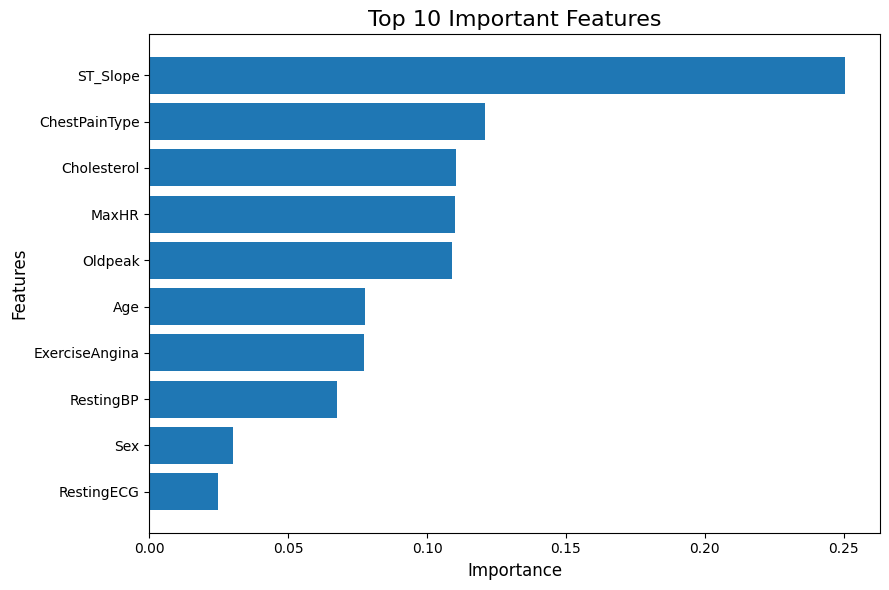


================ ARTIFICIAL NEURAL NETWORK ================


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Accuracy : 0.8804347826086957
F1 Score : 0.8942307692307693
ROC-AUC  : 0.915351506456241


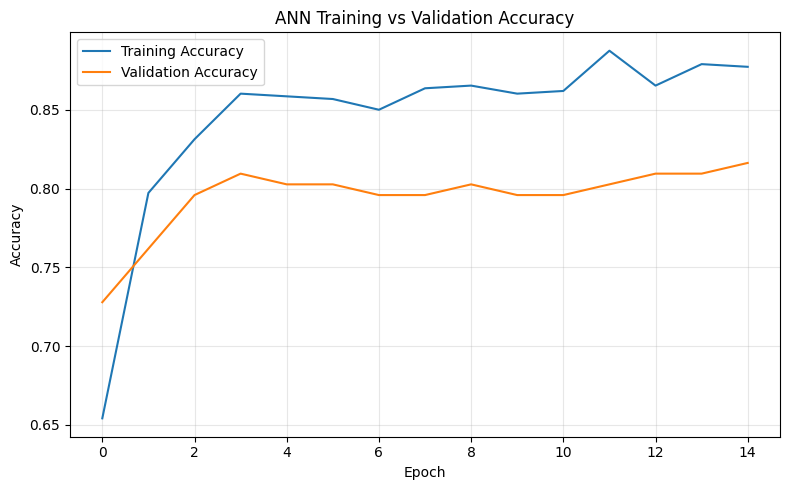


================ HYBRID MODEL ================

Best Threshold: 0.5204081632653061
Best F1: 0.9223300970873787

================ HYBRID MODEL RESULTS ================
Accuracy : 0.9130434782608695
F1 Score : 0.9223300970873787
ROC-AUC  : 0.9291009086561454

              MODEL COMPARISON
                 Model  Accuracy  F1 Score  ROC-AUC
0  Logistic Regression    0.8696    0.8879   0.8971
1        Random Forest    0.8913    0.9038   0.9285
2                  ANN    0.8804    0.8942   0.9154
3         Hybrid Model    0.9130    0.9223   0.9291


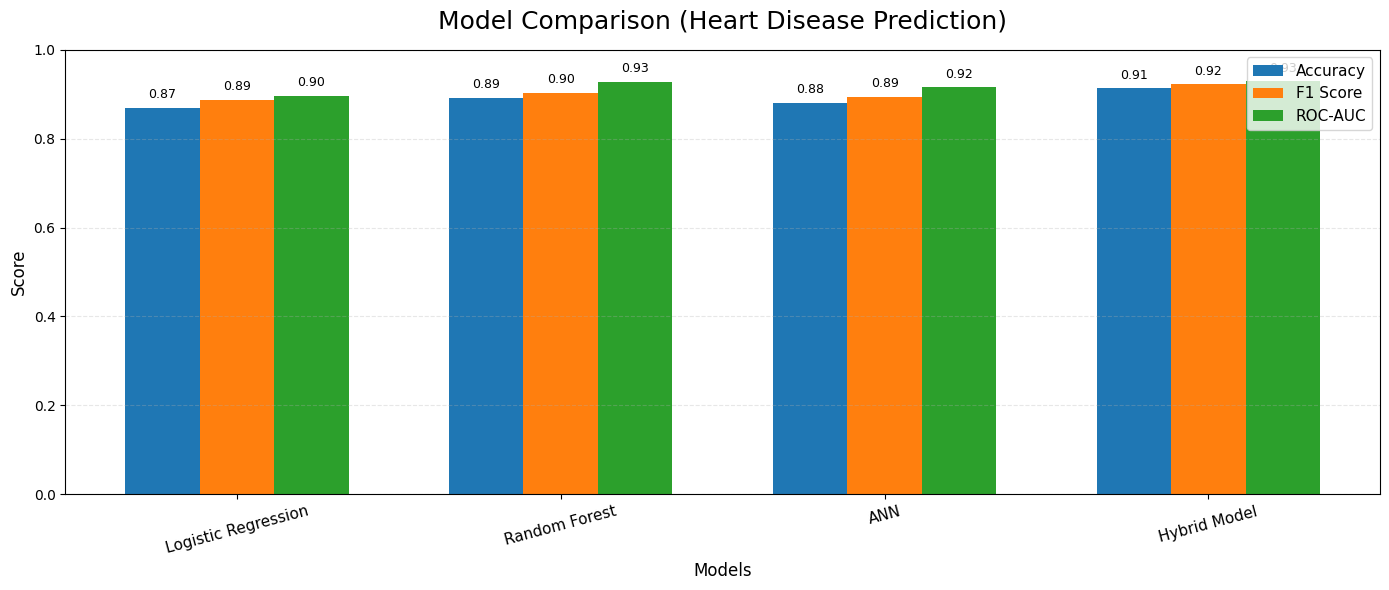


================ CLASSIFICATION REPORT ================
              precision    recall  f1-score   support

           0       0.91      0.89      0.90        82
           1       0.91      0.93      0.92       102

    accuracy                           0.91       184
   macro avg       0.91      0.91      0.91       184
weighted avg       0.91      0.91      0.91       184



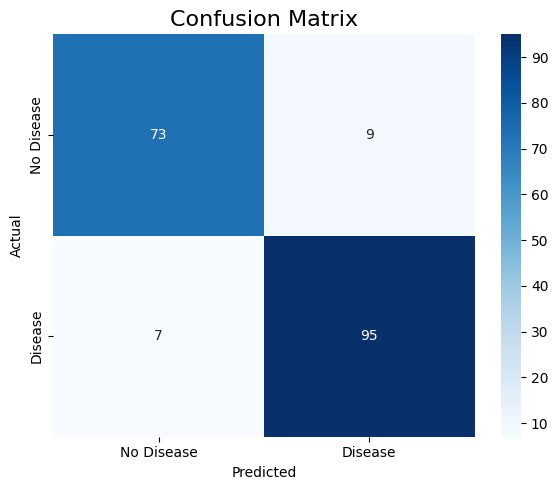

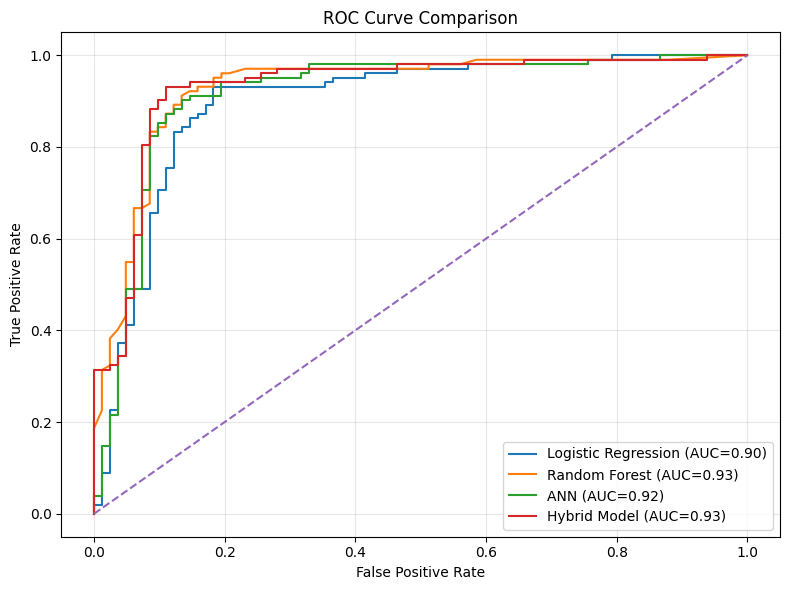

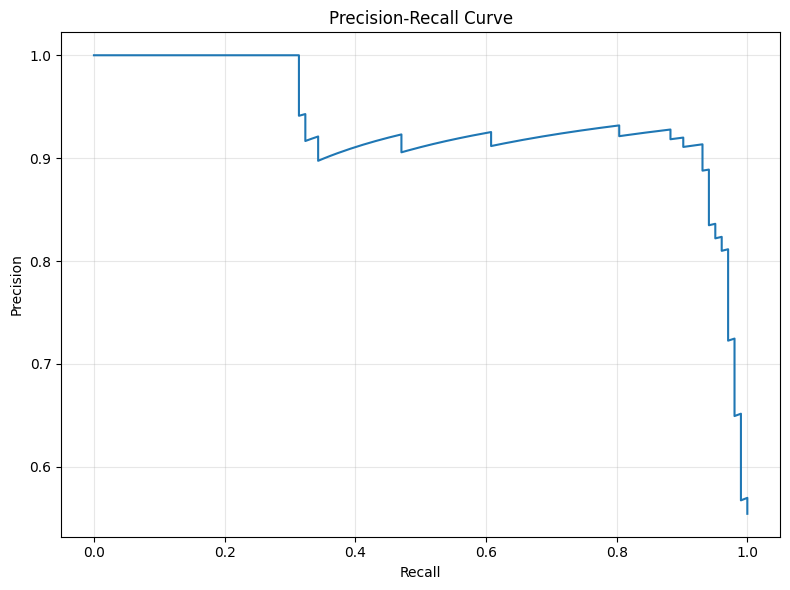

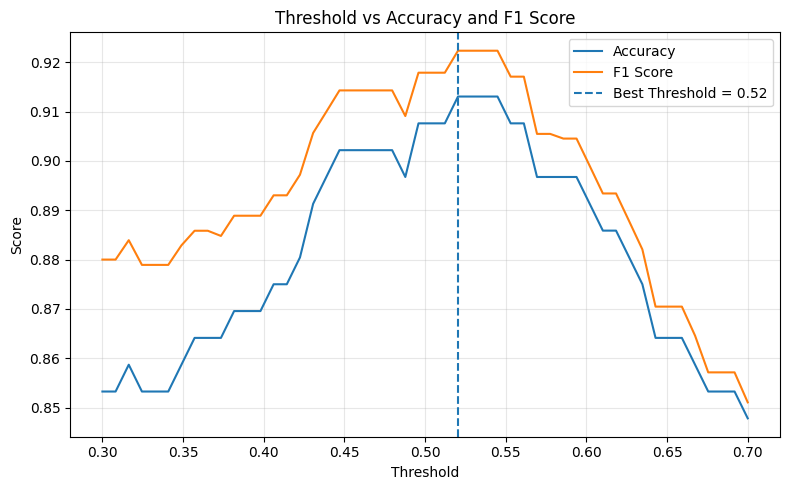


================ 5-FOLD CROSS VALIDATION ================
Fold F1 Scores:
[0.91089109 0.86699507 0.85849057 0.89952153 0.86792453]
Mean F1: 0.8807645576881276
Standard Deviation: 0.020542773375289227

================ SHAP ANALYSIS ================


<Figure size 640x480 with 0 Axes>

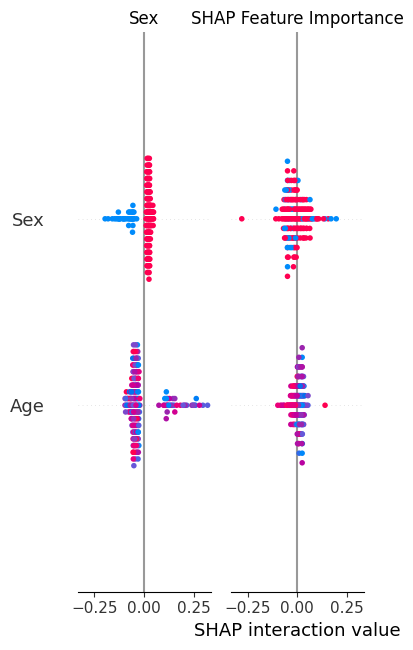



             FINAL RESULTS SUMMARY
              Model  Accuracy  F1 Score  ROC-AUC
Logistic Regression    0.8696    0.8879   0.8971
      Random Forest    0.8913    0.9038   0.9285
                ANN    0.8804    0.8942   0.9154
       Hybrid Model    0.9130    0.9223   0.9291

Best Hybrid Threshold: 0.5204

Hybrid Accuracy: 0.913
Hybrid F1 Score: 0.9223
Hybrid ROC-AUC: 0.9291

                  PROGRAM COMPLETED


In [1]:
# ============================================================
# HEART DISEASE PREDICTION - COMPLETE MODEL
# ============================================================


# ============================================================
# 1. INSTALL LIBRARIES
# ============================================================

!pip install shap -q
!pip install tensorflow scikit-learn seaborn -q


# ============================================================
# 2. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import tensorflow as tf

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)

from sklearn.preprocessing import (
    StandardScaler,
    LabelEncoder
)

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    f1_score,
    confusion_matrix
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping


# ============================================================
# 3. LOAD DATASET
# ============================================================

from google.colab import files

uploaded = files.upload()

df = pd.read_csv("heart.csv")

print("\n================ DATASET PREVIEW ================")
print(df.head())

print("\n================ DATASET INFORMATION ================")
print(df.info())

print("\n================ MISSING VALUES ================")
print(df.isnull().sum())


# ============================================================
# 4. ENCODE CATEGORICAL DATA
# ============================================================

categorical_cols = [
    "Sex",
    "ChestPainType",
    "RestingECG",
    "ExerciseAngina",
    "ST_Slope"
]

le = LabelEncoder()

for col in categorical_cols:
    df[col] = le.fit_transform(df[col])


print("\n================ ENCODED DATA ================")
print(df.head())


# ============================================================
# 5. SPLIT FEATURES AND TARGET
# ============================================================

X = df.drop("HeartDisease", axis=1)
y = df["HeartDisease"]

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget:")
print("HeartDisease")


# ============================================================
# 6. TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\n================ DATA SPLIT ================")

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])


# ============================================================
# 7. FEATURE SCALING
# ============================================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# ============================================================
# 8. MODEL 1 - LOGISTIC REGRESSION
# ============================================================

print("\n================ LOGISTIC REGRESSION ================")

lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr.fit(
    X_train_scaled,
    y_train
)

lr_prob = lr.predict_proba(
    X_test_scaled
)[:, 1]

lr_pred = (
    lr_prob > 0.5
).astype(int)

lr_accuracy = accuracy_score(
    y_test,
    lr_pred
)

lr_f1 = f1_score(
    y_test,
    lr_pred
)

lr_auc = roc_auc_score(
    y_test,
    lr_prob
)

print("Accuracy :", lr_accuracy)
print("F1 Score :", lr_f1)
print("ROC-AUC  :", lr_auc)


# ============================================================
# 9. MODEL 2 - RANDOM FOREST
# ============================================================

print("\n================ RANDOM FOREST ================")

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf.fit(
    X_train_scaled,
    y_train
)

rf_prob = rf.predict_proba(
    X_test_scaled
)[:, 1]

rf_pred = (
    rf_prob > 0.5
).astype(int)

rf_accuracy = accuracy_score(
    y_test,
    rf_pred
)

rf_f1 = f1_score(
    y_test,
    rf_pred
)

rf_auc = roc_auc_score(
    y_test,
    rf_prob
)

print("Accuracy :", rf_accuracy)
print("F1 Score :", rf_f1)
print("ROC-AUC  :", rf_auc)


# ============================================================
# 10. RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("\n================ TOP FEATURES ================")
print(
    feature_importance.head(10)
)


# ============================================================
# 11. FEATURE IMPORTANCE GRAPH
# ============================================================

top_features = feature_importance.head(10)

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.title(
    "Top 10 Important Features",
    fontsize=16
)

plt.xlabel(
    "Importance",
    fontsize=12
)

plt.ylabel(
    "Features",
    fontsize=12
)

plt.tight_layout()

plt.show()


# ============================================================
# 12. MODEL 3 - ARTIFICIAL NEURAL NETWORK
# ============================================================

print("\n================ ARTIFICIAL NEURAL NETWORK ================")

ann = Sequential([

    Dense(
        64,
        activation="relu",
        input_dim=X_train_scaled.shape[1]
    ),

    Dropout(0.30),

    Dense(
        32,
        activation="relu"
    ),

    Dropout(0.20),

    Dense(
        1,
        activation="sigmoid"
    )
])


ann.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)


history = ann.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.20,
    callbacks=[early_stop],
    verbose=0
)


ann_prob = ann.predict(
    X_test_scaled,
    verbose=0
).ravel()


ann_pred = (
    ann_prob > 0.5
).astype(int)


ann_accuracy = accuracy_score(
    y_test,
    ann_pred
)

ann_f1 = f1_score(
    y_test,
    ann_pred
)

ann_auc = roc_auc_score(
    y_test,
    ann_prob
)


print("Accuracy :", ann_accuracy)
print("F1 Score :", ann_f1)
print("ROC-AUC  :", ann_auc)


# ============================================================
# 13. ANN TRAINING GRAPH
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title(
    "ANN Training vs Validation Accuracy"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Accuracy"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 14. HYBRID MODEL
# ============================================================

print("\n================ HYBRID MODEL ================")

# Original weights:
# ANN = 0.5
# Random Forest = 0.8

ann_weight = 0.5
rf_weight = 0.8

# Normalize weights so final probability remains 0-1

final_prob = (
    ann_weight * ann_prob +
    rf_weight * rf_prob
) / (
    ann_weight + rf_weight
)


# ============================================================
# 15. THRESHOLD OPTIMIZATION
# ============================================================

thresholds = np.linspace(
    0.30,
    0.70,
    50
)

best_thresh = 0.50
best_f1 = 0

for t in thresholds:

    preds = (
        final_prob > t
    ).astype(int)

    current_f1 = f1_score(
        y_test,
        preds
    )

    if current_f1 > best_f1:

        best_f1 = current_f1
        best_thresh = t


print(
    "\nBest Threshold:",
    best_thresh
)

print(
    "Best F1:",
    best_f1
)


# ============================================================
# 16. FINAL HYBRID PREDICTION
# ============================================================

y_pred_final = (
    final_prob > best_thresh
).astype(int)


# ============================================================
# 17. HYBRID MODEL METRICS
# ============================================================

hybrid_accuracy = accuracy_score(
    y_test,
    y_pred_final
)

hybrid_f1 = f1_score(
    y_test,
    y_pred_final
)

hybrid_auc = roc_auc_score(
    y_test,
    final_prob
)


print("\n================ HYBRID MODEL RESULTS ================")

print(
    "Accuracy :",
    hybrid_accuracy
)

print(
    "F1 Score :",
    hybrid_f1
)

print(
    "ROC-AUC  :",
    hybrid_auc
)


# ============================================================
# 18. ALL MODEL RESULTS
# ============================================================

print("\n====================================================")
print("              MODEL COMPARISON")
print("====================================================")

results = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Random Forest",
        "ANN",
        "Hybrid Model"
    ],

    "Accuracy": [
        lr_accuracy,
        rf_accuracy,
        ann_accuracy,
        hybrid_accuracy
    ],

    "F1 Score": [
        lr_f1,
        rf_f1,
        ann_f1,
        hybrid_f1
    ],

    "ROC-AUC": [
        lr_auc,
        rf_auc,
        ann_auc,
        hybrid_auc
    ]
})


print(
    results.round(4)
)


# ============================================================
# 19. MODEL COMPARISON BAR CHART
# ============================================================

models = results["Model"].values

accuracy_values = results["Accuracy"].values
f1_values = results["F1 Score"].values
roc_auc_values = results["ROC-AUC"].values


x = np.arange(
    len(models)
)

width = 0.23


fig, ax = plt.subplots(
    figsize=(14, 6)
)


# Accuracy

bars1 = ax.bar(
    x - width,
    accuracy_values,
    width,
    label="Accuracy"
)


# F1 Score

bars2 = ax.bar(
    x,
    f1_values,
    width,
    label="F1 Score"
)


# ROC-AUC

bars3 = ax.bar(
    x + width,
    roc_auc_values,
    width,
    label="ROC-AUC"
)


# Title

ax.set_title(
    "Model Comparison (Heart Disease Prediction)",
    fontsize=18,
    pad=15
)


# Axis labels

ax.set_xlabel(
    "Models",
    fontsize=12
)

ax.set_ylabel(
    "Score",
    fontsize=12
)


# X-axis

ax.set_xticks(x)

ax.set_xticklabels(
    models,
    rotation=15,
    fontsize=11
)


# Y-axis

ax.set_ylim(
    0,
    1.0
)


# Grid

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)


# Add values above bars

for bars in [
    bars1,
    bars2,
    bars3
]:

    for bar in bars:

        height = bar.get_height()

        ax.text(
            bar.get_x()
            + bar.get_width() / 2,

            height + 0.015,

            f"{height:.2f}",

            ha="center",

            va="bottom",

            fontsize=9
        )


# Legend

ax.legend(
    loc="upper right",
    fontsize=11
)


plt.tight_layout()

plt.show()


# ============================================================
# 20. CLASSIFICATION REPORT
# ============================================================

print("\n================ CLASSIFICATION REPORT ================")

print(
    classification_report(
        y_test,
        y_pred_final
    )
)


# ============================================================
# 21. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred_final
)


plt.figure(
    figsize=(6, 5)
)


sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "No Disease",
        "Disease"
    ],
    yticklabels=[
        "No Disease",
        "Disease"
    ]
)


plt.title(
    "Confusion Matrix",
    fontsize=16
)

plt.xlabel(
    "Predicted"
)

plt.ylabel(
    "Actual"
)

plt.tight_layout()

plt.show()


# ============================================================
# 22. ROC CURVES - ALL MODELS
# ============================================================

lr_fpr, lr_tpr, _ = roc_curve(
    y_test,
    lr_prob
)

rf_fpr, rf_tpr, _ = roc_curve(
    y_test,
    rf_prob
)

ann_fpr, ann_tpr, _ = roc_curve(
    y_test,
    ann_prob
)

hybrid_fpr, hybrid_tpr, _ = roc_curve(
    y_test,
    final_prob
)


plt.figure(
    figsize=(8, 6)
)


plt.plot(
    lr_fpr,
    lr_tpr,
    label=f"Logistic Regression (AUC={lr_auc:.2f})"
)

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest (AUC={rf_auc:.2f})"
)

plt.plot(
    ann_fpr,
    ann_tpr,
    label=f"ANN (AUC={ann_auc:.2f})"
)

plt.plot(
    hybrid_fpr,
    hybrid_tpr,
    label=f"Hybrid Model (AUC={hybrid_auc:.2f})"
)


plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)


plt.title(
    "ROC Curve Comparison"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 23. PRECISION-RECALL CURVE
# ============================================================

precision, recall, _ = precision_recall_curve(
    y_test,
    final_prob
)


plt.figure(
    figsize=(8, 6)
)


plt.plot(
    recall,
    precision
)


plt.title(
    "Precision-Recall Curve"
)

plt.xlabel(
    "Recall"
)

plt.ylabel(
    "Precision"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 24. THRESHOLD VS ACCURACY
# ============================================================

acc_list = []

f1_list = []


for t in thresholds:

    preds = (
        final_prob > t
    ).astype(int)

    acc_list.append(
        accuracy_score(
            y_test,
            preds
        )
    )

    f1_list.append(
        f1_score(
            y_test,
            preds
        )
    )


plt.figure(
    figsize=(8, 5)
)


plt.plot(
    thresholds,
    acc_list,
    label="Accuracy"
)

plt.plot(
    thresholds,
    f1_list,
    label="F1 Score"
)


plt.axvline(
    best_thresh,
    linestyle="--",
    label=f"Best Threshold = {best_thresh:.2f}"
)


plt.title(
    "Threshold vs Accuracy and F1 Score"
)

plt.xlabel(
    "Threshold"
)

plt.ylabel(
    "Score"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 25. 5-FOLD CROSS VALIDATION
# ============================================================

print("\n================ 5-FOLD CROSS VALIDATION ================")

X_cv = df.drop(
    "HeartDisease",
    axis=1
)

y_cv = df["HeartDisease"]


cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


rf_cv = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)


scores = cross_val_score(
    rf_cv,
    X_cv,
    y_cv,
    cv=cv,
    scoring="f1"
)


print(
    "Fold F1 Scores:"
)

print(
    scores
)


print(
    "Mean F1:",
    scores.mean()
)


print(
    "Standard Deviation:",
    scores.std()
)


# ============================================================
# 26. SHAP ANALYSIS
# ============================================================

print("\n================ SHAP ANALYSIS ================")


# Train RF on unscaled data for easier SHAP interpretation

rf_shap = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_shap.fit(
    X_train,
    y_train
)


explainer = shap.TreeExplainer(
    rf_shap
)


shap_values = explainer.shap_values(
    X_test
)


# Handle different SHAP versions

if isinstance(shap_values, list):

    shap_for_plot = shap_values[1]

else:

    shap_for_plot = shap_values


# SHAP Summary Plot

plt.figure()

shap.summary_plot(
    shap_for_plot,
    X_test,
    feature_names=X.columns,
    show=False
)

plt.title(
    "SHAP Feature Importance"
)

plt.tight_layout()

plt.show()


# ============================================================
# 27. FINAL RESULTS SUMMARY
# ============================================================

print("\n")
print("====================================================")
print("             FINAL RESULTS SUMMARY")
print("====================================================")

print(
    results.round(4).to_string(index=False)
)

print("\nBest Hybrid Threshold:", round(best_thresh, 4))

print(
    "\nHybrid Accuracy:",
    round(hybrid_accuracy, 4)
)

print(
    "Hybrid F1 Score:",
    round(hybrid_f1, 4)
)

print(
    "Hybrid ROC-AUC:",
    round(hybrid_auc, 4)
)

print("\n====================================================")
print("                  PROGRAM COMPLETED")
print("====================================================")